# 01 — Data: MetroPT-3 sensors, data quality and failure signature

**Goal**: understand how the air production unit behaves, check the data quality, and see what a reported failure looks like before building any detector.

**Key findings**

- 1,516,948 readings of 15 signals (7 analog, 8 digital) from February 1 to September 1, 2020, with no missing values inside the file.
- The readings are spaced **~10 s apart, not 1 s** as the dataset documentation states. The file holds one tenth of the documented 15.2 M rows.
- Coverage is uneven. **331 interruptions longer than one minute** add up to ~38 days (18% of the period), and **8 stretches of 6 h or more** where every analog sensor repeats the same value (stalled logger) add up to ~7 days. Both must be excluded or flagged before training and scoring.
- In normal service the compressor cycles every ~20 minutes: **under load** (~6 A, 15% of the time), **offloaded** (~4 A), then **off** (~0 A).
- During the four reported air leaks this cycle disappears. The compressor stays **under load 99.5% of the time** and the oil runs **~13 °C hotter**: a leak is a *collective* anomaly (a change of regime), not an isolated spike.
- **8 sustained-load episodes of one hour or more occur outside the reported failure windows**, including one the morning after failure 3, before its maintenance. The failure reports are therefore an incomplete ground truth. The evaluation will have to score detection per failure event and report out-of-window alarms separately rather than treat them all as errors.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # paths are relative to the project root (data/, docs/)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from metrobench.data import (ANALOG, DESCRIPTIONS, DIGITAL, FAILURES, UNITS, failure_mask, find_gaps, find_runs,
                             frozen_mask, load)
from metrobench.plotstyle import FAILURE, GAP, SERIES, shade_failures, use_style

use_style()
FIG = Path("docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Dataset

Source: [UCI Machine Learning Repository, MetroPT-3](https://archive.ics.uci.edu/dataset/791/metropt+3+dataset), readings from the air production unit (APU) of a compressor on a Porto metro train, released with Veloso *et al.*, *Scientific Data* 9, 764 (2022). `metrobench.data.load` downloads the archive on first use and caches it as Parquet (analog signals as float32, digital as int8: 22 MB instead of 218 MB).

In [2]:
df = load()
sensors = pd.DataFrame({
    "type": ["analog"] * len(ANALOG) + ["digital"] * len(DIGITAL),
    "unit": [UNITS.get(c, "0/1") for c in ANALOG + DIGITAL],
    "description": [DESCRIPTIONS[c] for c in ANALOG + DIGITAL],
}, index=ANALOG + DIGITAL)
print(f"{len(df):,} readings from {df.index.min()} to {df.index.max()}, {df.isna().sum().sum()} missing values")
sensors

1,516,948 readings from 2020-02-01 00:00:00 to 2020-09-01 03:59:50, 0 missing values


,type,unit,description
TP2,analog,bar,pressure on the compressor
TP3,analog,bar,pressure at the pneumatic panel
H1,analog,bar,pressure drop when the cyclonic separator filt...
DV_pressure,analog,bar,pressure drop when the air-dryer towers discha...
Reservoirs,analog,bar,downstream reservoir pressure (should track TP3)
Oil_temperature,analog,°C,compressor oil temperature
Motor_current,analog,A,"current of one motor phase (~0 off, ~4 offload..."
COMP,digital,0/1,air intake valve signal (active = no intake: c...
DV_eletric,digital,0/1,outlet valve signal (active = compressor under...
Towers,digital,0/1,which air-dryer tower is drying (0 = tower one...


In [3]:
df[ANALOG].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.37,3.25,-0.03,-0.01,-0.01,-0.01,10.68
TP3,1516948.0,8.98,0.64,0.73,8.49,8.96,9.49,10.30
H1,1516948.0,7.57,3.33,-0.04,8.25,8.78,9.37,10.29
DV_pressure,1516948.0,0.06,0.38,-0.03,-0.02,-0.02,-0.02,9.84
Reservoirs,1516948.0,8.99,0.64,0.71,8.49,8.96,9.49,10.30
Oil_temperature,1516948.0,62.64,6.52,15.40,57.78,62.70,67.25,89.05
Motor_current,1516948.0,2.05,2.30,0.02,0.04,0.05,3.81,9.30


`TP3` and `Reservoirs` are the same measurement in practice (median absolute difference 0.002 bar), and `H1` mirrors `TP2` (correlation −0.96). The digital signals are mostly redundant with the analog ones: `MPG` and `COMP` follow each other, `DV_eletric` is the loaded state that `Motor_current` also shows.

In [4]:
print("median |TP3 - Reservoirs| =", round(float((df.TP3 - df.Reservoirs).abs().median()), 4), "bar")
df[ANALOG].corr().round(2)

median |TP3 - Reservoirs| = 0.002 bar


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
TP2,1.00,-0.01,-0.96,0.42,-0.01,0.25,0.70
TP3,-0.01,1.00,0.22,-0.15,1.00,0.40,0.41
H1,-0.96,0.22,1.00,-0.43,0.23,-0.16,-0.60
DV_pressure,0.42,-0.15,-0.43,1.00,-0.15,0.34,0.30
Reservoirs,-0.01,1.00,0.23,-0.15,1.00,0.40,0.41
Oil_temperature,0.25,0.40,-0.16,0.34,0.40,1.00,0.53
Motor_current,0.70,0.41,-0.60,0.30,0.41,0.53,1.00


## 2. Sampling and coverage

In [5]:
step = df.index.to_series().diff().dt.total_seconds()
step.value_counts().head(6).rename("readings").to_frame().rename_axis("seconds since previous reading")

,readings
seconds since previous reading,
10.0,1337521
9.0,128277
12.0,38321
13.0,7988
11.0,4471
21.0,10


The dominant step is 10 s (88% of readings), with 9–13 s jitter. The original index of the CSV runs 0, 10, 20…, which suggests the file was downsampled by 10 from the 1 Hz recording.

In [6]:
gaps = find_gaps(df.index, threshold="60s")
frozen = find_runs(frozen_mask(df), min_duration="6h")
period = df.index.max() - df.index.min()

coverage = pd.DataFrame({
    "stretches": [len(gaps), len(frozen)],
    "total_days": [gaps.duration.sum() / pd.Timedelta("1D"), frozen.duration.sum() / pd.Timedelta("1D")],
}, index=["gaps > 1 min", "frozen readings >= 6 h"])
coverage["share_of_period_%"] = 100 * coverage.total_days / (period / pd.Timedelta("1D"))
coverage.round(1)

,stretches,total_days,share_of_period_%
gaps > 1 min,331,37.9,17.8
frozen readings >= 6 h,8,7.0,3.3


In [7]:
gaps.sort_values("duration", ascending=False).head(5)

,start,end,duration
122,2020-04-25 01:10:51,2020-04-27 01:12:49,2 days 00:01:58
219,2020-06-27 10:53:07,2020-06-28 23:07:43,1 days 12:14:36
35,2020-02-28 23:57:08,2020-03-01 04:00:09,1 days 04:03:01
290,2020-08-04 07:42:28,2020-08-05 08:23:01,1 days 00:40:33
172,2020-05-24 00:39:23,2020-05-25 01:14:14,1 days 00:34:51


In [8]:
frozen

,start,end,duration
0,2020-04-17 09:20:43,2020-04-18 00:18:07,0 days 14:57:24
1,2020-04-20 04:49:17,2020-04-21 01:16:52,0 days 20:27:35
2,2020-05-26 09:19:36,2020-05-27 13:43:45,1 days 04:24:09
3,2020-05-27 13:53:52,2020-05-28 03:16:28,0 days 13:22:36
4,2020-06-12 02:01:56,2020-06-12 17:06:06,0 days 15:04:10
5,2020-06-22 15:06:21,2020-06-25 05:08:35,2 days 14:02:14
6,2020-07-21 13:45:12,2020-07-21 22:03:16,0 days 08:18:04
7,2020-07-22 06:43:44,2020-07-22 13:04:24,0 days 06:20:40


A frozen stretch is not the compressor being off: when it stops, the pressures decay and the oil cools, so the analog readings still change. Seven analog values identical for hours point to a stalled logger. The stretch of April 17 ends 18 minutes into the reported window of failure 1.

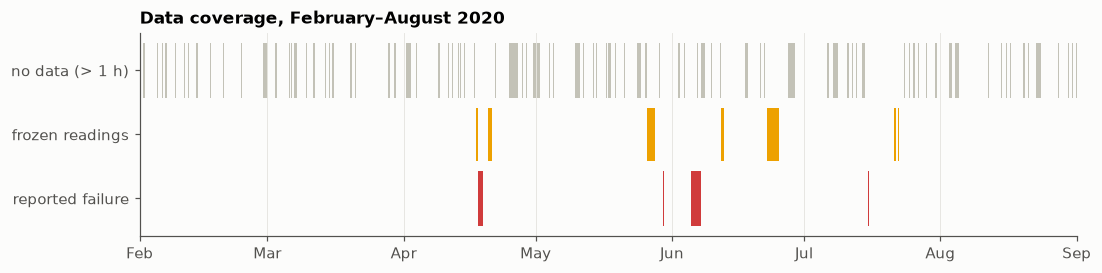

In [9]:
fig, ax = plt.subplots(figsize=(11, 2.4))
for (s, e) in gaps[gaps.duration > pd.Timedelta("1h")][["start", "end"]].itertuples(index=False):
    ax.axvspan(s, e, ymin=0.68, ymax=0.95, color=GAP, lw=0)
for (s, e) in frozen[["start", "end"]].itertuples(index=False):
    ax.axvspan(s, e, ymin=0.37, ymax=0.63, color=SERIES[3], lw=0)
for (s, e) in FAILURES[["start", "end"]].itertuples(index=False):
    ax.axvspan(s, e, ymin=0.05, ymax=0.32, color=FAILURE, lw=0)
ax.set_yticks([0.185, 0.5, 0.815], ["reported failure", "frozen readings", "no data (> 1 h)"])
ax.set_ylim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlim(df.index.min(), df.index.max())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Data coverage, February–August 2020")
fig.savefig(FIG / "01_coverage.png")
plt.show()

## 3. Normal operating cycle

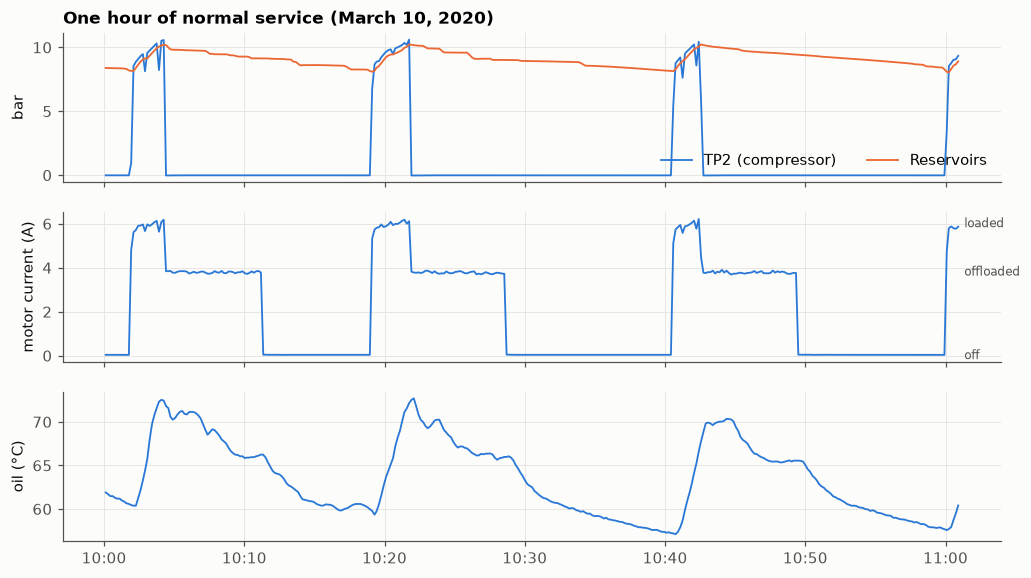

In [10]:
hour = df.loc["2020-03-10 10:00":"2020-03-10 11:00"]
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
axes[0].plot(hour.index, hour.TP2, label="TP2 (compressor)")
axes[0].plot(hour.index, hour.Reservoirs, label="Reservoirs")
axes[0].set_ylabel("bar")
axes[0].legend(loc="lower right", ncol=2)
axes[1].plot(hour.index, hour.Motor_current, color=SERIES[0])
axes[1].set_ylabel("motor current (A)")
for level, name in [(6, "loaded"), (3.8, "offloaded"), (0, "off")]:
    axes[1].annotate(name, (hour.index[-1], level), xytext=(4, 0), textcoords="offset points",
                     va="center", fontsize=8, color="#52514e", annotation_clip=False)
axes[2].plot(hour.index, hour.Oil_temperature, color=SERIES[0])
axes[2].set_ylabel("oil (°C)")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[0].set_title("One hour of normal service (March 10, 2020)")
fig.savefig(FIG / "01_normal_cycle.png")
plt.show()

Each cycle starts when the pressure falls to ~8.2 bar (`MPG`). The motor runs **under load** (~6 A) and pushes the reservoir pressure up to ~10 bar in about 2–3 minutes. It then runs **offloaded** (~4 A) for ~10 minutes and **stops** until the pressure drops again. The oil heats up during the loaded phase and cools during the rest of the cycle.

In [11]:
state = pd.cut(df.Motor_current, [-np.inf, 1, 5, np.inf], labels=["off", "offloaded", "loaded"])
share = state.value_counts(normalize=True).mul(100).round(1)
print("share of readings by motor state (%):", share.to_dict())
print("share of readings with DV_eletric active (loaded): "
      f"{100 * df.DV_eletric.mean():.1f}%")

share of readings by motor state (%): {'off': 54.6, 'offloaded': 30.2, 'loaded': 15.2}
share of readings with DV_eletric active (loaded): 16.1%


## 4. The reported failures

In [12]:
FAILURES.assign(duration=FAILURES.end - FAILURES.start,
                readings=[len(df.loc[s:e]) for s, e in zip(FAILURES.start, FAILURES.end)])

,start,end,duration,readings
failure,,,,
1,2020-04-18 00:00:00,2020-04-18 23:59:00,0 days 23:59:00,8657
2,2020-05-29 23:30:00,2020-05-30 06:00:00,0 days 06:30:00,2360
3,2020-06-05 10:00:00,2020-06-07 14:30:00,2 days 04:30:00,17315
4,2020-07-15 14:30:00,2020-07-15 19:00:00,0 days 04:30:00,1622


The documentation table numbers the second failure "#1" and dates its maintenance "30 Apr", a month *before* the failure. The failures are renumbered 1–4 here, and the maintenance dates are not used. Failure 3 is followed by a 21-hour gap in the recording.

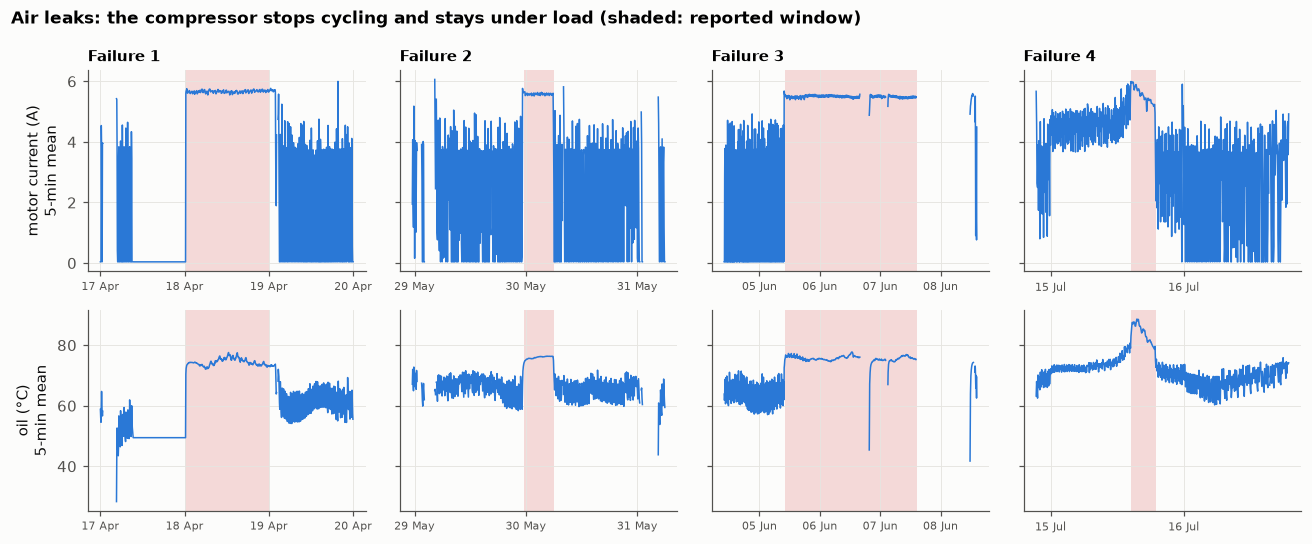

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharey="row")
for j, (i, (s, e)) in enumerate(FAILURES[["start", "end"]].iterrows()):
    w = df.loc[s - pd.Timedelta("1D"): e + pd.Timedelta("1D")].resample("5min").mean()
    for k, col in enumerate(["Motor_current", "Oil_temperature"]):
        ax = axes[k, j]
        ax.plot(w.index, w[col], color=SERIES[0], lw=1)
        ax.axvspan(s, e, color=FAILURE, alpha=0.18, lw=0)
        ax.xaxis.set_major_locator(mdates.DayLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        ax.tick_params(axis="x", labelsize=7)
    axes[0, j].set_title(f"Failure {i}", fontsize=10)
axes[0, 0].set_ylabel("motor current (A)\n5-min mean")
axes[1, 0].set_ylabel("oil (°C)\n5-min mean")
fig.suptitle("Air leaks: the compressor stops cycling and stays under load (shaded: reported window)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "01_failures.png")
plt.show()

In [14]:
in_failure = failure_mask(df.index)
signature = df.groupby(in_failure)[["Motor_current", "Oil_temperature", "TP2", "Reservoirs", "DV_eletric", "COMP", "LPS"]].mean().T
signature.columns = ["normal", "reported failure"]
signature.round(3)

,normal,reported failure
Motor_current,1.980,5.532
Oil_temperature,62.383,75.598
TP2,1.232,8.115
Reservoirs,8.999,8.290
DV_eletric,0.144,0.995
COMP,0.854,0.004
LPS,0.003,0.024


The 5-minute averages make the signature plain: the motor current plateaus at ~5.5 A instead of oscillating, and the oil stays at ~75 °C. The air leak makes the reservoirs lose pressure continuously, so the compressor never reaches the cut-out pressure and never offloads. The reservoir pressure itself drops only slightly (8.3 vs 9.0 bar on average). The low-pressure alarm `LPS` (below 7 bar) is active in only 2.4% of failure readings, so the existing on-board alarm would miss these leaks.

Failure 4 differs from the others: from midnight on July 15, more than 14 hours before the reported window, the compressor is already loaded 35–57% of the time (against ~12% on a typical day) and the oil temperature rises steadily, peaking at ~88 °C just after the window opens. Detecting a failure *before* its reported start is therefore plausible for some events, which is why lead time is part of the evaluation.

## 5. Sustained load outside the reported windows

The failure signature is easy to state as a rule: *the compressor has been loaded for most of the last 30 minutes*. Applying it to the whole period shows how complete the failure reports are.

In [15]:
loaded_30min = df.DV_eletric.rolling("30min").mean() > 0.9
episodes = find_runs(loaded_30min, max_step="60s", min_duration="1h")
episodes["share_in_reported_failure"] = [in_failure.loc[s:e].mean().round(2) for s, e in zip(episodes.start, episodes.end)]
episodes["duration"] = episodes.duration.dt.round("1min")
episodes

,start,end,duration,share_in_reported_failure
0,2020-03-12 00:43:02,2020-03-12 11:52:48,0 days 11:10:00,0.00
1,2020-03-27 07:39:06,2020-03-27 11:41:09,0 days 04:02:00,0.00
2,2020-03-28 07:49:20,2020-03-28 08:49:39,0 days 01:00:00,0.00
3,2020-03-28 23:05:32,2020-03-29 19:49:14,0 days 20:44:00,0.00
4,2020-04-12 12:17:27,2020-04-12 23:38:59,0 days 11:22:00,0.00
5,2020-04-18 00:45:27,2020-04-19 01:58:34,1 days 01:13:00,0.92
6,2020-05-13 14:11:00,2020-05-14 00:56:48,0 days 10:46:00,0.00
7,2020-05-19 22:47:24,2020-05-20 19:48:20,0 days 21:01:00,0.00
8,2020-05-29 23:41:51,2020-05-30 05:59:44,0 days 06:18:00,1.00
9,2020-06-05 10:15:26,2020-06-06 15:55:17,1 days 05:40:00,1.00


In [16]:
outside = episodes[episodes.share_in_reported_failure == 0]
print(f"{len(episodes)} sustained-load episodes >= 1 h, {len(outside)} entirely outside reported failures "
      f"({outside.duration.sum()} in total)")

15 sustained-load episodes >= 1 h, 8 entirely outside reported failures (3 days 09:24:00 in total)


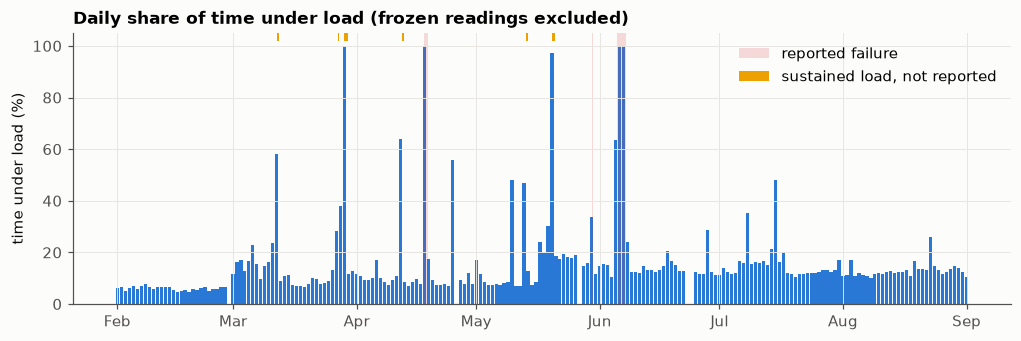

In [17]:
in_frozen = failure_mask(df.index, frozen)  # rows inside the frozen stretches of section 2
daily = df.DV_eletric[~in_frozen].resample("1D").mean().mul(100)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(daily.index, daily.values, width=0.8, color=SERIES[0])
shade_failures(ax, FAILURES)
for i, (s, e) in enumerate(outside[["start", "end"]].itertuples(index=False)):
    ax.axvspan(s, e, ymin=0.97, ymax=1, color=SERIES[3], lw=0, label="sustained load, not reported" if i == 0 else None)
ax.set_ylabel("time under load (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right")
ax.set_title("Daily share of time under load (frozen readings excluded)")
fig.savefig(FIG / "01_daily_load.png")
plt.show()

In a typical day the compressor is loaded ~12% of the time; failure days stand out at 40–100%. Several unreported episodes are just as long as the shorter reported failures, such as March 28–29 (21 h) and May 19–20 (21 h). The episode on June 8 follows failure 3, after the recording gap and before the maintenance reported for that afternoon, so it is most likely the same leak continuing.

## 6. Consequences for the benchmark

- **Unit of time**: 10 s readings are far finer than the phenomenon (hours). Detectors will work on resampled windows (for example 1–5 minutes) with features that describe the cycle: share of time loaded, cycle length, oil temperature level.
- **Data quality**: gaps longer than one minute break windows; frozen stretches are removed from training and from scoring.
- **Training data**: unsupervised and semi-supervised detectors learn "normal" from a period that excludes the reported failures. The unreported sustained-load episodes stay in that period, as they would in production, and act as label noise.
- **Evaluation**: a detector is scored per failure event (detected or not, and how early), with a budget on false alarms per week. Alarms during unreported sustained-load episodes are reported separately rather than counted as plain false positives.
- **Baseline to beat**: the 30-minute sustained-load rule above. It detects all four failures by construction, so any learned method has to justify itself with earlier detection or fewer alarms.